In [1]:
import xarray as xr
import numpy as np
import glob
import matplotlib.pyplot as plt
import matplotlib.cm as mcm
import matplotlib.dates as mdates
from datetime import datetime, timedelta
jet = mcm.get_cmap('jet') if isinstance(mcm.get_cmap('jet'), str) else mcm.get_cmap('jet')

/tmp/ipykernel_102123/3461964483.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = mcm.get_cmap('jet') if isinstance(mcm.get_cmap('jet'), str) else mcm.get_cmap('jet')


In [29]:
def compare_runs_avg_over_season(datasets, lat_val=20, season='spring', run_names=None, lon_val=195):
    if run_names is None:
        run_names = [f'Run {i+1}' for i in range(len(datasets))]

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

    fig, ax = plt.subplots(figsize=(12, 6))

    Ulimhigh = 0.01
    Ulimlow = -0.01

    # Calculate the full 3-month slice (assuming 30 days per month)
    total_hours = 3 * 30 * 24
    time_array = np.arange(0, (total_hours + 1)) / 24

    for run_idx, (run_data, run_name) in enumerate(zip(datasets, run_names)):
        key = f'U_plot2_120_100_{lat_val}_{season}'
        if key in run_data:
            data = run_data[key]

            if len(data.time) >= total_hours:
                # Average over the entire 3-month period
                U_data_avg = data.isel(time=slice(0, total_hours + 1)).mean(dim='time').values

                ax.plot(time_array, [U_data_avg] * len(time_array), color=colors[run_idx % len(colors)],
                        label=run_name, linewidth=1.5)
            else:
                print(f"Warning: Not enough data in {run_name} for full 3-month average")
        else:
            print(f"Warning: Key '{key}' not found in {run_name}")

    ax.set_ylabel(r'$dUdz$ / s$^{-1}$', fontsize=12)
    ax.set_ylim(Ulimlow, Ulimhigh)
    ax.set_xlabel('Days', fontsize=12)

    season_str = "Mar-May" if season == "spring" else "Dec-Feb"
    ax.set_title(f"Average Vertical Wind Gradient (120-100 km)\nlat={lat_val}°N, lon={lon_val}°E, {season_str}",
                 fontsize=14)

    ax.grid(True, which='major', linestyle='-', alpha=0.7)
    ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)

    ax.legend(loc='upper right')

    plt.tight_layout()

    return fig, ax

def plot_seasonal_comparison(climate_data, smed_data, lat_values=None, seasons=None):
    if lat_values is None:
        lat_values = [20, -50]
    
    if seasons is None:
        seasons = ['spring', 'winter']

    fig, axes = plt.subplots(len(lat_values), len(seasons), figsize=(15, 10))

    if len(lat_values) == 1 and len(seasons) == 1:
        axes = np.array([[axes]])
    elif len(lat_values) == 1:
        axes = np.array([axes])
    elif len(seasons) == 1:
        axes = np.array([axes]).T

    for lat_idx, lat_val in enumerate(lat_values):
        for season_idx, season in enumerate(seasons):
            ax = axes[lat_idx, season_idx]

            timestep1 = (30*24)
            time_array = np.arange(0, (10*24 + 1)) / 24

            datasets = [
                (climate_data, 'Climate', 'red'),
                (smed_data, 'SMed', 'blue')
            ]
            
            for data, label, color in datasets:
                if f'U_plot2_120_100_{lat_val}_{season}' in data:
                    U_data = data[f'U_plot2_120_100_{lat_val}_{season}'].isel(
                        time=slice(timestep1, timestep1 + (10*24 + 1))).values
                    ax.plot(time_array, U_data, color=color, label=label)
                else:
                    print(f"Warning: Key 'U_plot2_120_100_{lat_val}_{season}' not found")

            ax.set_ylabel(r'$dUdz$ / s$^{-1}$')
            ax.set_ylim(-0.02, 0.01)
            ax.grid(True)

            season_name = 'Mar-May' if season == 'spring' else 'Dec-Feb'
            ax.set_title(f'({lat_val}°)\n{season_name}')

            if lat_idx == 0 and season_idx == 0:
                ax.legend(loc='upper right')

            if lat_idx == len(lat_values) - 1:
                ax.set_xlabel('Days')

    fig.suptitle('Wind Gradient (120-100 km) Comparison: Climate vs SMed Data', 
                fontsize=16, y=0.98)
    
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    
    return fig, axes

def process_seasonal_data(climate_path, janfeb_path, smed_path):
    ds_months_sets = [['03', '04', '05'], ['12', '01', '02']]
    Monthstr_sets = [['Mar', 'Apr', 'May'], ['Dec', 'Jan', 'Feb']]
    season_set = ['spring', 'winter']

    plotdata_all = {
        'climate': {}, 
        'smed': {}      
    }
    for season_idx, months in enumerate(ds_months_sets):
        season_name = season_set[season_idx]
        Monthstr = Monthstr_sets[season_idx]
        
        file_paths = []
        for month in months:
            if month in ['01', '02']:
                pattern = janfeb_path.format(month=month)
            else:
                pattern = climate_path.format(month=month)

            matched_files = glob.glob(pattern)
            print(f"Found {len(matched_files)} climate files for {month} using pattern: {pattern}")
            file_paths.extend(matched_files)
        
        print(f"Processing climate {season_name} season with {len(file_paths)} total files")
        if len(file_paths) == 0:
            print(f"Warning: No climate files found for {season_name} season")
            continue
            
        ds = xr.open_mfdataset(file_paths, combine='by_coords')

        process_dataset(ds, season_name, plotdata_all['climate'])

    if smed_path:
        for season_idx, months in enumerate(ds_months_sets):
            season_name = season_set[season_idx]
            Monthstr = Monthstr_sets[season_idx]
            
            file_paths = []
            for month in months:
                pattern = smed_path.format(month=month)
                matched_files = glob.glob(pattern)
                print(f"Found {len(matched_files)} SMed files for {month} using pattern: {pattern}")
                file_paths.extend(matched_files)
            
            print(f"Processing SMed {season_name} season with {len(file_paths)} total files")
            if len(file_paths) == 0:
                print(f"Warning: No SMed files found for {season_name} season")
                continue
                
            ds = xr.open_mfdataset(file_paths, combine='by_coords')

            process_dataset(ds, season_name, plotdata_all['smed'])
    
    return plotdata_all

def process_dataset(ds, season_name, plotdata):
    
    lon = ds['lon']
    lat = ds['lat']
    lev = ds['lev']
    temp = ds['T']
    timee = ds['time']   
    
    U = ds['U']

    metal_ions = {}
    if all(var in ds for var in ['Fep', 'Mgp', 'Nap']):
        Fep = ds['Fep']
        Mgp = ds['Mgp']
        Nap = ds['Nap']
        Mp = Fep + 2*Mgp + Nap
        Mpdens = (Mp * 1e-6 * 100 * lev) / (1.380503e-23 * temp)
        metal_ions['Mp'] = Mp
        metal_ions['Mpdens'] = Mpdens
    
    #----------------------------------------------------
    for lat_val in [-60, 20]:
        lat_idx = np.abs(lat - lat_val).argmin()
        
        lon_val = 195
        lon_idx = np.abs(lon - lon_val).argmin()
        
        alt_110_idx = 48
        
        plotdata[f'U_plot2_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_110_idx)
        
        if 'Mpdens' in metal_ions:
            plotdata[f'Mpdens_plot2_{lat_val}_{season_name}'] = metal_ions['Mpdens'].sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_110_idx)
        
        alt_113_idx = 47
        alt_108_idx = 49
        
        plotdata[f'U_plot2_113_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_113_idx)
        plotdata[f'U_plot2_108_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_108_idx)
        
        alt_120_idx = 43
        alt_100_idx = 52
        
        plotdata[f'U_plot2_120_100_{lat_val}_{season_name}'] = (
            (U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_120_idx)) - 
            (U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_100_idx))
        ) / 2e4  # wind shear is change in U / 20km   units = s-1

Found 31 climate files for 03 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-03-*.nc
Found 30 climate files for 04 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-04-*.nc
Found 31 climate files for 05 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-05-*.nc
Processing climate spring season with 92 total files
Found 31 climate files for 12 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-12-*.nc
Found 31 climate files for 01 using pattern: /resstore/b0243/Data/Sporadic_E/FX2101f19f19mg16NaFeMgiontransport_OUTPUT/atm/hist/FX2101f19f19mg16NaFeMgiontransport.cam.h2.2100-01-*.nc
Found 28 climate files for 02 using pattern: /re

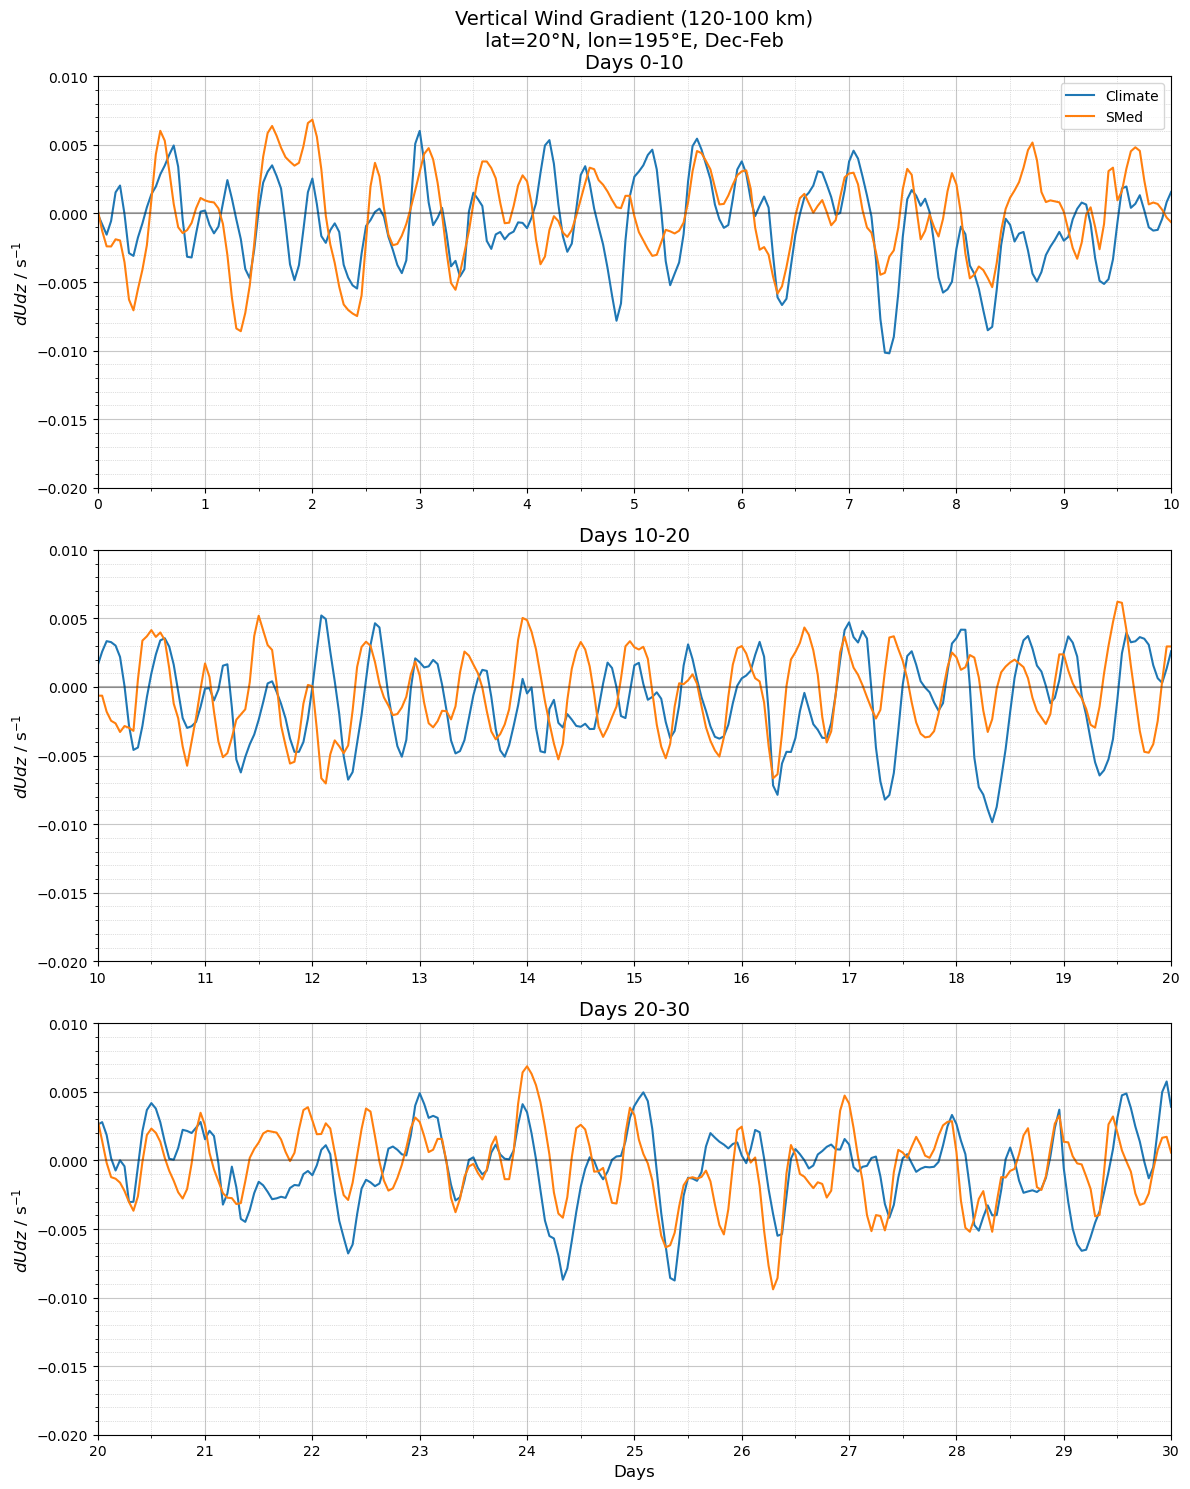

In [30]:
climate_path = '/resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-{month}-*.nc'
janfeb_path = '/resstore/b0243/Data/Sporadic_E/FX2101f19f19mg16NaFeMgiontransport_OUTPUT/atm/hist/FX2101f19f19mg16NaFeMgiontransport.cam.h2.2100-{month}-*.nc'
smed_path = '/resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-{month}-*.nc'


all_data = process_seasonal_data(climate_path, janfeb_path, smed_path)

fig, axes = compare_runs_same_location(
    [all_data['climate'], all_data['smed']], 
    lat_val=20,
    season='winter',  
    run_names=['Climate', 'SMed']
)
plt.savefig('Wind_Gradient_Comparison.png', dpi=300, bbox_inches='tight')
plt.show()


# fig, axes = plot_seasonal_comparison(all_data['climate'], all_data['smed'])
# plt.savefig('Dataset_Comparison_Matrix.png', dpi=300, bbox_inches='tight')
# plt.show()

Found 31 climate files for 03 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-03-*.nc
Found 30 climate files for 04 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-04-*.nc
Found 31 climate files for 05 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-05-*.nc
Processing climate spring season with 92 total files
Found 31 SMed files for 03 using pattern: /resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-03-*.nc
Found 30 SMed files for 04 using pattern: /resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-04-*.nc
Found 31 SMed files for 05 using pattern: /resstore/b0243/Data/S

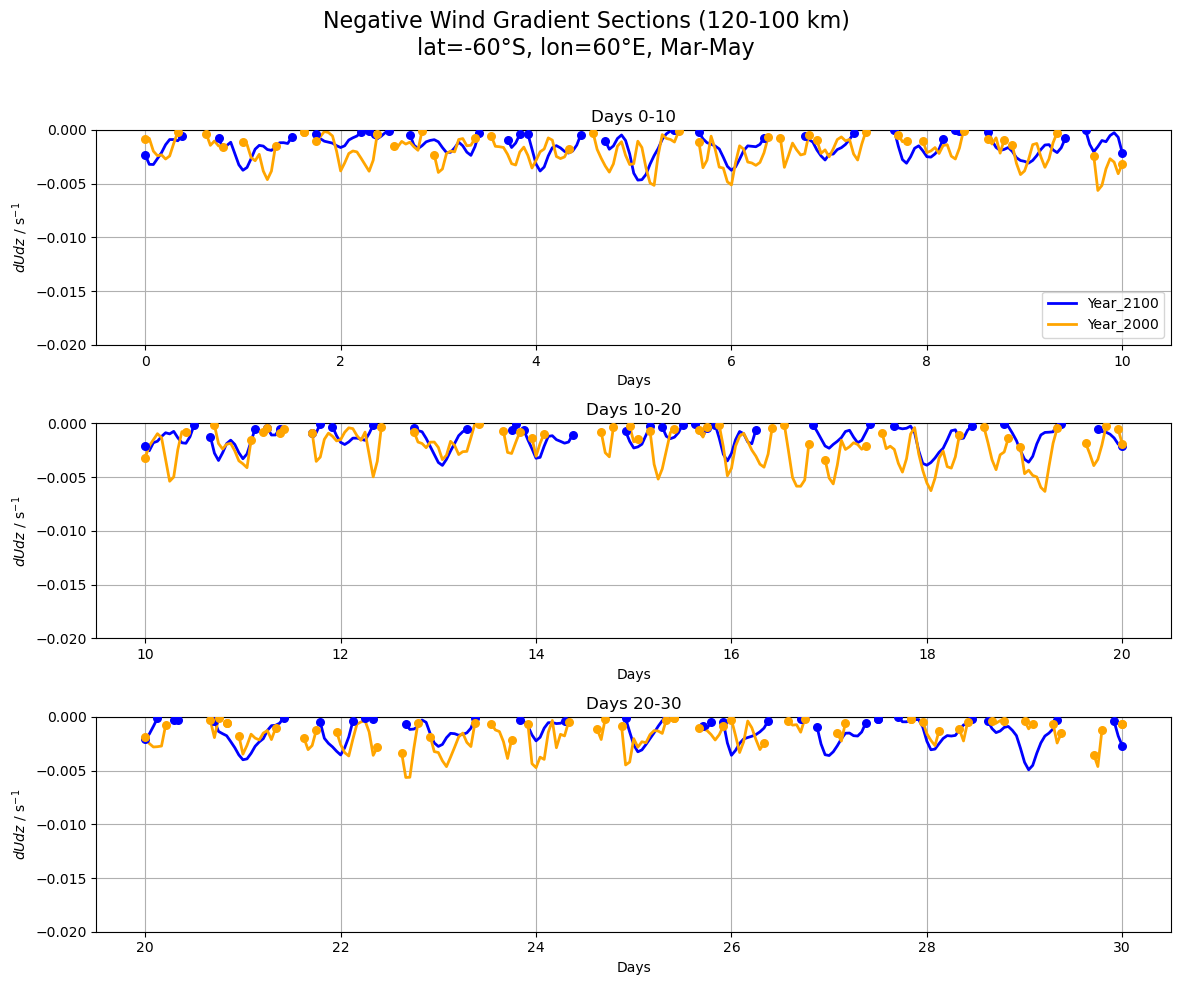

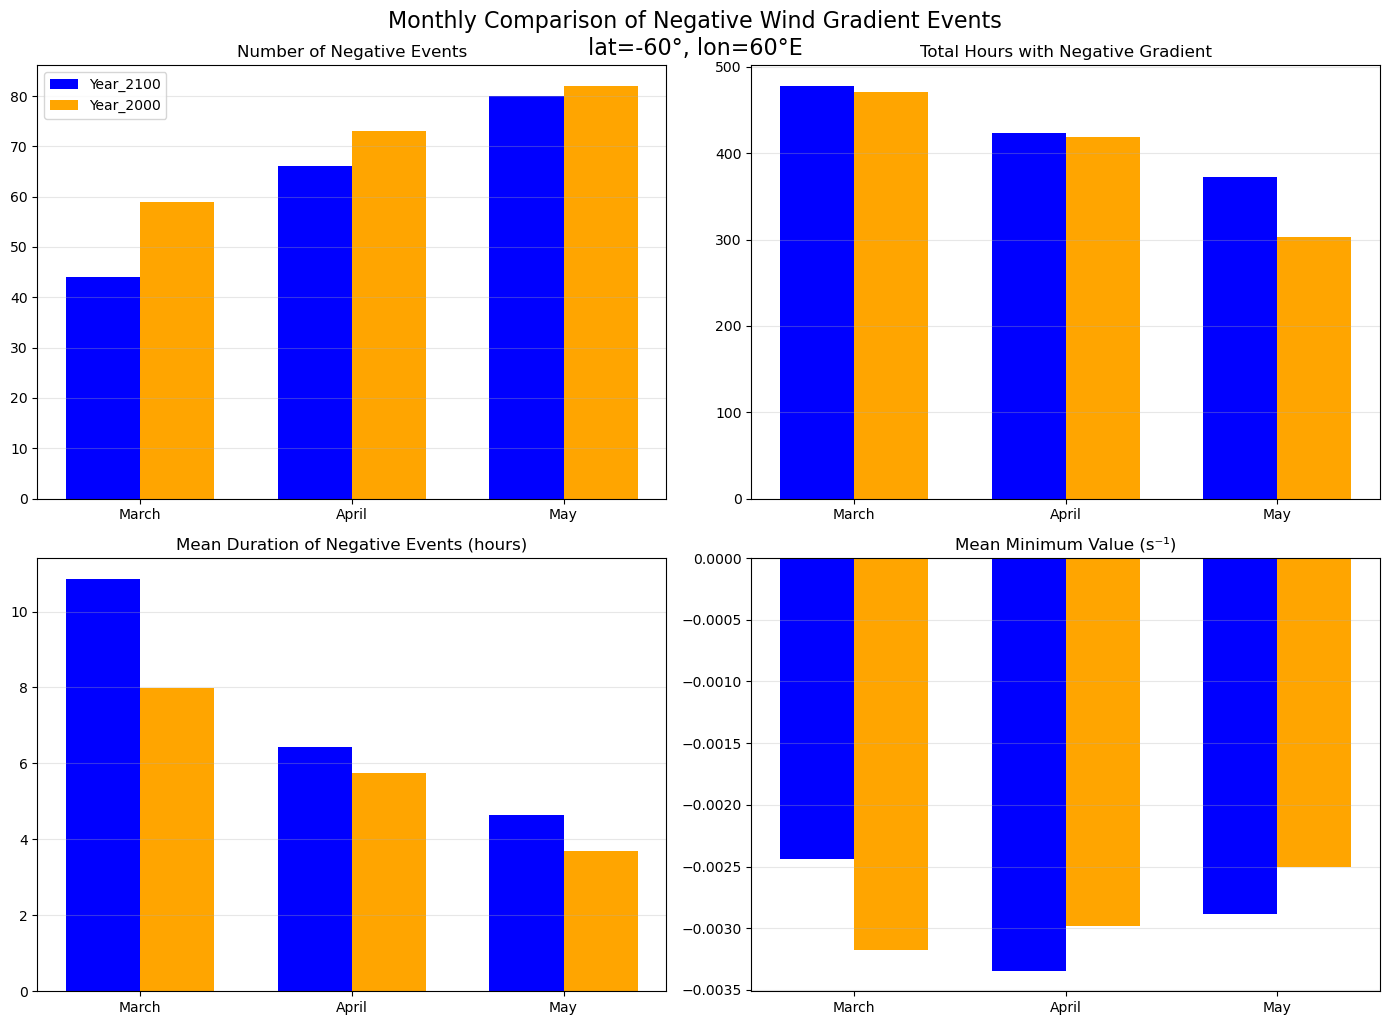

Analysis completed successfully!


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import glob

# Define constants for years
YEAR_2100 = 'Year_2100'
YEAR_2000 = 'Year_2000'

def process_dataset(ds, season_name, plotdata):
    """
    Process dataset to extract wind gradient data.
    This function is adapted from the original code.
    """
    lon = ds['lon']
    lat = ds['lat']
    lev = ds['lev']
    temp = ds['T']
    timee = ds['time']   
    
    U = ds['U']

    metal_ions = {}
    if all(var in ds for var in ['Fep', 'Mgp', 'Nap']):
        Fep = ds['Fep']
        Mgp = ds['Mgp']
        Nap = ds['Nap']
        Mp = Fep + 2*Mgp + Nap
        Mpdens = (Mp * 1e-6 * 100 * lev) / (1.380503e-23 * temp)
        metal_ions['Mp'] = Mp
        metal_ions['Mpdens'] = Mpdens
    
    #----------------------------------------------------
    for lat_val in [-60, 20]:
        lat_idx = np.abs(lat - lat_val).argmin()
        
        lon_val = 60  # Changed from 195 to 60
        lon_idx = np.abs(lon - lon_val).argmin()
        
        alt_110_idx = 48
        
        plotdata[f'U_plot2_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_110_idx)
        
        if 'Mpdens' in metal_ions:
            plotdata[f'Mpdens_plot2_{lat_val}_{season_name}'] = metal_ions['Mpdens'].sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_110_idx)
        
        alt_113_idx = 47
        alt_108_idx = 49
        
        plotdata[f'U_plot2_113_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_113_idx)
        plotdata[f'U_plot2_108_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_108_idx)
        
        alt_120_idx = 43
        alt_100_idx = 52
        
        plotdata[f'U_plot2_120_100_{lat_val}_{season_name}'] = (
            (U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_120_idx)) - 
            (U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_100_idx))
        ) / 2e4  # wind shear is change in U / 20km   units = s-1

def process_spring_data(climate_path, smed_path):
    """
    Process only spring months (March, April, May) data
    """
    spring_months = ['03', '04', '05']
    Monthstr = ['Mar', 'Apr', 'May']
    season_name = 'spring'

    plotdata_all = {
        YEAR_2100: {}, 
        YEAR_2000: {}      
    }
    
    # Process climate data for spring
    file_paths = []
    for month in spring_months:
        pattern = climate_path.format(month=month)
        matched_files = glob.glob(pattern)
        print(f"Found {len(matched_files)} climate files for {month} using pattern: {pattern}")
        file_paths.extend(matched_files)
    
    print(f"Processing climate {season_name} season with {len(file_paths)} total files")
    if len(file_paths) > 0:
        ds = xr.open_mfdataset(file_paths, combine='by_coords')
        process_dataset(ds, season_name, plotdata_all[YEAR_2100])
    else:
        print(f"Warning: No climate files found for {season_name} season")
    
    # Process SMed data for spring if available
    if smed_path:
        file_paths = []
        for month in spring_months:
            pattern = smed_path.format(month=month)
            matched_files = glob.glob(pattern)
            print(f"Found {len(matched_files)} SMed files for {month} using pattern: {pattern}")
            file_paths.extend(matched_files)
        
        print(f"Processing SMed {season_name} season with {len(file_paths)} total files")
        if len(file_paths) > 0:
            ds = xr.open_mfdataset(file_paths, combine='by_coords')
            process_dataset(ds, season_name, plotdata_all[YEAR_2000])
        else:
            print(f"Warning: No SMed files found for {season_name} season")
    
    return plotdata_all

def plot_negative_wind_gradient_spring(climate_data, smed_data, lat_val=-60, time_periods=None):
    """
    Plot only the negative sections of wind gradient data for easier comparison
    specifically for spring months (March, April, May).
    
    Parameters:
    -----------
    climate_data : dict
        Dictionary containing climate data
    smed_data : dict
        Dictionary containing SMed data
    lat_val : int
        Latitude value to plot
    time_periods : list of tuples
        List of (start_day, end_day) tuples defining the time periods to plot
    """
    if time_periods is None:
        time_periods = [(0, 10), (10, 20), (20, 30)]
    
    # Set up the figure with subplots for each time period
    fig, axes = plt.subplots(len(time_periods), 1, figsize=(12, 10), sharex=False)
    if len(time_periods) == 1:
        axes = [axes]  # Make sure axes is always a list for consistent indexing
    
    colors = {YEAR_2100: 'blue', YEAR_2000: 'orange'}
    season = 'spring'  # Specifically set to spring for March-May
    
    for i, (start_day, end_day) in enumerate(time_periods):
        ax = axes[i]
        
        # Calculate start and end timesteps (hours)
        start_hour = start_day * 24
        end_hour = end_day * 24 + 1
        time_array = np.arange(start_hour, end_hour) / 24
        
        datasets = [
            (climate_data, YEAR_2100),
            (smed_data, YEAR_2000)
        ]
        
        # For the negative values plot
        for data, label in datasets:
            key = f'U_plot2_120_100_{lat_val}_{season}'
            if key in data:
                # Extract the data for the time period
                wind_data = data[key].isel(time=slice(start_hour, end_hour)).values
                
                # Create a masked array where positive values are masked
                negative_only = np.ma.masked_where(wind_data >= 0, wind_data)
                
                # Plot only the negative values
                ax.plot(time_array, negative_only, color=colors[label], label=f"{label}", 
                       linewidth=2)
                
                # Add points to mark the beginning and end of each negative section
                mask = wind_data < 0
                # Find the starts and ends of negative sections
                if any(mask):  # Only proceed if there are negative values
                    starts_ends = np.where(np.diff(np.concatenate(([False], mask, [False]))))[0]
                    
                    # Group starts and ends
                    for j in range(0, len(starts_ends) - 1, 2):
                        start_idx = starts_ends[j]
                        end_idx = starts_ends[j+1] - 1
                        # Mark the start and end points
                        ax.scatter([time_array[start_idx], time_array[end_idx]], 
                                  [wind_data[start_idx], wind_data[end_idx]], 
                                  color=colors[label], s=30, zorder=5)
            else:
                print(f"Warning: Key '{key}' not found in {label} data")
        
        ax.set_ylabel(r'$dUdz$ / s$^{-1}$')
        ax.set_ylim(-0.02, 0)  # Only show negative range
        ax.grid(True)
        ax.set_title(f'Days {start_day}-{end_day}')
        
        # Add zero line for reference
        ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
        
        if i == 0:
            ax.legend(loc='lower right')
        
        ax.set_xlabel('Days')
    
    fig.suptitle(f'Negative Wind Gradient Sections (120-100 km)\nlat={lat_val}°S, lon=60°E, Mar-May', 
                fontsize=16, y=0.98)
    
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    
    return fig, axes

def analyze_monthly_negative_events(climate_data, smed_data, lat_val=-60):
    """
    Analyze negative wind gradient events by month (March, April, May)
    
    Parameters:
    -----------
    climate_data : dict
        Dictionary containing climate data
    smed_data : dict
        Dictionary containing SMed data
    lat_val : int
        Latitude value to analyze
        
    Returns:
    --------
    dict
        Dictionary with monthly statistics about negative wind gradient events
    """
    season = 'spring'
    key = f'U_plot2_120_100_{lat_val}_{season}'
    
    # Assuming each month has 30 days for simplicity
    month_ranges = {
        'March': (0, 30*24),
        'April': (30*24, 60*24), 
        'May': (60*24, 90*24)
    }
    
    results = {}
    
    for data_name, data in [(YEAR_2100, climate_data), (YEAR_2000, smed_data)]:
        if key in data:
            wind_data = data[key].values
            
            monthly_stats = {}
            
            for month_name, (start_hour, end_hour) in month_ranges.items():
                # Extract month data if available
                if len(wind_data) > start_hour:
                    month_data = wind_data[start_hour:min(end_hour, len(wind_data))]
                    
                    # Identify negative regions
                    negative_mask = month_data < 0
                    
                    if any(negative_mask):  # Only proceed if there are negative values
                        # Find the borders of negative regions
                        change_points = np.where(np.diff(np.concatenate(([False], negative_mask, [False]))))[0]
                        
                        # Group into start-end pairs
                        event_edges = [(change_points[i], change_points[i+1]-1) for i in range(0, len(change_points), 2)]
                        
                        # Calculate statistics for each event
                        event_stats = []
                        for start, end in event_edges:
                            event_data = month_data[start:end+1]
                            event_stats.append({
                                'start_hour': start + start_hour,
                                'end_hour': end + start_hour,
                                'duration_hours': end - start + 1,
                                'min_value': np.min(event_data),
                                'mean_value': np.mean(event_data),
                                'area': np.sum(event_data)  # Approximate integral of the negative region
                            })
                        
                        monthly_stats[month_name] = {
                            'num_events': len(event_stats),
                            'total_negative_hours': sum(e['duration_hours'] for e in event_stats),
                            'mean_duration': np.mean([e['duration_hours'] for e in event_stats]) if event_stats else 0,
                            'median_duration': np.median([e['duration_hours'] for e in event_stats]) if event_stats else 0,
                            'mean_min_value': np.mean([e['min_value'] for e in event_stats]) if event_stats else 0,
                            'events': event_stats
                        }
                    else:
                        monthly_stats[month_name] = {
                            'num_events': 0,
                            'total_negative_hours': 0,
                            'mean_duration': 0,
                            'median_duration': 0,
                            'mean_min_value': 0,
                            'events': []
                        }
                else:
                    monthly_stats[month_name] = {
                        'num_events': 0,
                        'total_negative_hours': 0,
                        'mean_duration': 0,
                        'median_duration': 0,
                        'mean_min_value': 0,
                        'events': []
                    }
            
            results[data_name] = monthly_stats
        else:
            print(f"Warning: Key '{key}' not found in {data_name} data")
    
    return results

def plot_monthly_negative_events_comparison(analysis_results, figsize=(14, 10)):
    """
    Create bar charts comparing negative event statistics by month
    """
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    axes = axes.flatten()
    
    months = ['March', 'April', 'May']
    metrics = [
        ('num_events', 'Number of Negative Events'),
        ('total_negative_hours', 'Total Hours with Negative Gradient'),
        ('mean_duration', 'Mean Duration of Negative Events (hours)'),
        ('mean_min_value', 'Mean Minimum Value (s⁻¹)')
    ]
    
    bar_width = 0.35
    index = np.arange(len(months))
    
    for i, (metric, title) in enumerate(metrics):
        ax = axes[i]
        
        climate_values = []
        smed_values = []
        
        for month in months:
            if YEAR_2100 in analysis_results and month in analysis_results[YEAR_2100]:
                climate_values.append(analysis_results[YEAR_2100][month][metric])
            else:
                climate_values.append(0)
                
            if YEAR_2000 in analysis_results and month in analysis_results[YEAR_2000]:
                smed_values.append(analysis_results[YEAR_2000][month][metric])
            else:
                smed_values.append(0)
        
        ax.bar(index - bar_width/2, climate_values, bar_width, label=YEAR_2100, color='blue')
        ax.bar(index + bar_width/2, smed_values, bar_width, label=YEAR_2000, color='orange')
        
        ax.set_xticks(index)
        ax.set_xticklabels(months)
        ax.set_title(title)
        ax.grid(True, axis='y', alpha=0.3)
        
        if i == 0:
            ax.legend()
    
    plt.tight_layout()
    fig.suptitle('Monthly Comparison of Negative Wind Gradient Events\nlat=-60°, lon=60°E', y=1.02, fontsize=16)
    
    return fig, axes

# Example usage:
if __name__ == "__main__":
    # Example paths (uncomment and modify these to run the code)
    # climate_path = '/path/to/climate/data/file-{month}.nc'
    # smed_path = '/path/to/smed/data/file-{month}.nc'
    
    # Using the actual paths from the error message
    climate_path = '/resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-{month}-*.nc'
    smed_path = '/resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-{month}-*.nc'
    
    spring_data = process_spring_data(climate_path, smed_path)
    
    # Plot negative wind gradient for spring
    fig1, axes1 = plot_negative_wind_gradient_spring(spring_data[YEAR_2100], spring_data[YEAR_2000])
    # plt.savefig('negative_wind_gradient_spring.png')
    # plt.close(fig1)
    
    # Analyze monthly negative events
    monthly_analysis = analyze_monthly_negative_events(spring_data[YEAR_2100], spring_data[YEAR_2000])
    
    # Plot monthly analysis comparison
    fig2, axes2 = plot_monthly_negative_events_comparison(monthly_analysis)
    # plt.savefig('monthly_negative_events_comparison.png')
    # plt.close(fig2)

    plt.show()
    
    print("Analysis completed successfully!")

Found 31 climate files for 03 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-03-*.nc
Found 30 climate files for 04 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-04-*.nc
Found 31 climate files for 05 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-05-*.nc
Processing climate spring season with 92 total files
Found 31 SMed files for 03 using pattern: /resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-03-*.nc
Found 30 SMed files for 04 using pattern: /resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-04-*.nc
Found 31 SMed files for 05 using pattern: /resstore/b0243/Data/S

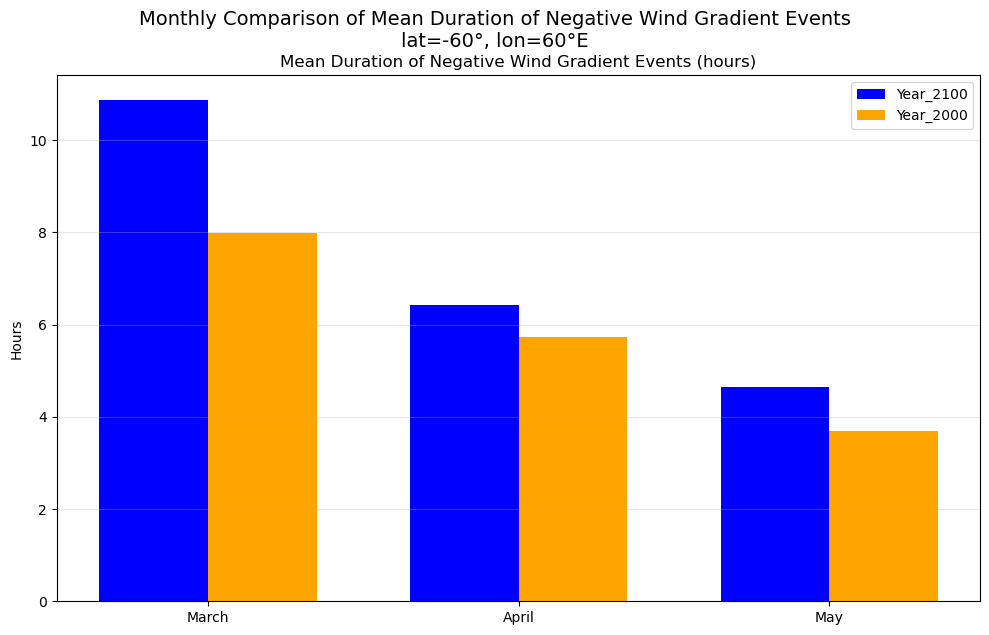

Analysis completed successfully!


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import glob

# Define constants for years
YEAR_2100 = 'Year_2100'
YEAR_2000 = 'Year_2000'

def process_dataset(ds, season_name, plotdata):
    """
    Process dataset to extract wind gradient data.
    This function is adapted from the original code.
    """
    lon = ds['lon']
    lat = ds['lat']
    lev = ds['lev']
    temp = ds['T']
    timee = ds['time']   
    
    U = ds['U']

    metal_ions = {}
    if all(var in ds for var in ['Fep', 'Mgp', 'Nap']):
        Fep = ds['Fep']
        Mgp = ds['Mgp']
        Nap = ds['Nap']
        Mp = Fep + 2*Mgp + Nap
        Mpdens = (Mp * 1e-6 * 100 * lev) / (1.380503e-23 * temp)
        metal_ions['Mp'] = Mp
        metal_ions['Mpdens'] = Mpdens
    
    #----------------------------------------------------
    for lat_val in [-60, 20]:
        lat_idx = np.abs(lat - lat_val).argmin()
        
        lon_val = 60  # Changed from 195 to 60
        lon_idx = np.abs(lon - lon_val).argmin()
        
        alt_110_idx = 48
        
        plotdata[f'U_plot2_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_110_idx)
        
        if 'Mpdens' in metal_ions:
            plotdata[f'Mpdens_plot2_{lat_val}_{season_name}'] = metal_ions['Mpdens'].sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_110_idx)
        
        alt_113_idx = 47
        alt_108_idx = 49
        
        plotdata[f'U_plot2_113_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_113_idx)
        plotdata[f'U_plot2_108_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_108_idx)
        
        alt_120_idx = 43
        alt_100_idx = 52
        
        plotdata[f'U_plot2_120_100_{lat_val}_{season_name}'] = (
            (U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_120_idx)) - 
            (U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_100_idx))
        ) / 2e4  # wind shear is change in U / 20km   units = s-1

def process_spring_data(climate_path, smed_path):
    """
    Process only spring months (March, April, May) data
    """
    spring_months = ['03', '04', '05']
    Monthstr = ['Mar', 'Apr', 'May']
    season_name = 'spring'

    plotdata_all = {
        YEAR_2100: {}, 
        YEAR_2000: {}      
    }
    
    # Process climate data for spring
    file_paths = []
    for month in spring_months:
        pattern = climate_path.format(month=month)
        matched_files = glob.glob(pattern)
        print(f"Found {len(matched_files)} climate files for {month} using pattern: {pattern}")
        file_paths.extend(matched_files)
    
    print(f"Processing climate {season_name} season with {len(file_paths)} total files")
    if len(file_paths) > 0:
        ds = xr.open_mfdataset(file_paths, combine='by_coords')
        process_dataset(ds, season_name, plotdata_all[YEAR_2100])
    else:
        print(f"Warning: No climate files found for {season_name} season")
    
    # Process SMed data for spring if available
    if smed_path:
        file_paths = []
        for month in spring_months:
            pattern = smed_path.format(month=month)
            matched_files = glob.glob(pattern)
            print(f"Found {len(matched_files)} SMed files for {month} using pattern: {pattern}")
            file_paths.extend(matched_files)
        
        print(f"Processing SMed {season_name} season with {len(file_paths)} total files")
        if len(file_paths) > 0:
            ds = xr.open_mfdataset(file_paths, combine='by_coords')
            process_dataset(ds, season_name, plotdata_all[YEAR_2000])
        else:
            print(f"Warning: No SMed files found for {season_name} season")
    
    return plotdata_all

def analyze_monthly_negative_events(climate_data, smed_data, lat_val=-60):
    """
    Analyze negative wind gradient events by month (March, April, May)
    
    Parameters:
    -----------
    climate_data : dict
        Dictionary containing climate data
    smed_data : dict
        Dictionary containing SMed data
    lat_val : int
        Latitude value to analyze
        
    Returns:
    --------
    dict
        Dictionary with monthly statistics about negative wind gradient events
    """
    season = 'spring'
    key = f'U_plot2_120_100_{lat_val}_{season}'
    
    # Assuming each month has 30 days for simplicity
    month_ranges = {
        'March': (0, 30*24),
        'April': (30*24, 60*24), 
        'May': (60*24, 90*24)
    }
    
    results = {}
    
    for data_name, data in [(YEAR_2100, climate_data), (YEAR_2000, smed_data)]:
        if key in data:
            wind_data = data[key].values
            
            monthly_stats = {}
            
            for month_name, (start_hour, end_hour) in month_ranges.items():
                # Extract month data if available
                if len(wind_data) > start_hour:
                    month_data = wind_data[start_hour:min(end_hour, len(wind_data))]
                    
                    # Identify negative regions
                    negative_mask = month_data < 0
                    
                    if any(negative_mask):  # Only proceed if there are negative values
                        # Find the borders of negative regions
                        change_points = np.where(np.diff(np.concatenate(([False], negative_mask, [False]))))[0]
                        
                        # Group into start-end pairs
                        event_edges = [(change_points[i], change_points[i+1]-1) for i in range(0, len(change_points), 2)]
                        
                        # Calculate statistics for each event
                        event_stats = []
                        for start, end in event_edges:
                            event_data = month_data[start:end+1]
                            event_stats.append({
                                'start_hour': start + start_hour,
                                'end_hour': end + start_hour,
                                'duration_hours': end - start + 1,
                                'min_value': np.min(event_data),
                                'mean_value': np.mean(event_data),
                                'area': np.sum(event_data)  # Approximate integral of the negative region
                            })
                        
                        monthly_stats[month_name] = {
                            'num_events': len(event_stats),
                            'total_negative_hours': sum(e['duration_hours'] for e in event_stats),
                            'mean_duration': np.mean([e['duration_hours'] for e in event_stats]) if event_stats else 0,
                            'median_duration': np.median([e['duration_hours'] for e in event_stats]) if event_stats else 0,
                            'mean_min_value': np.mean([e['min_value'] for e in event_stats]) if event_stats else 0,
                            'events': event_stats
                        }
                    else:
                        monthly_stats[month_name] = {
                            'num_events': 0,
                            'total_negative_hours': 0,
                            'mean_duration': 0,
                            'median_duration': 0,
                            'mean_min_value': 0,
                            'events': []
                        }
                else:
                    monthly_stats[month_name] = {
                        'num_events': 0,
                        'total_negative_hours': 0,
                        'mean_duration': 0,
                        'median_duration': 0,
                        'mean_min_value': 0,
                        'events': []
                    }
            
            results[data_name] = monthly_stats
        else:
            print(f"Warning: Key '{key}' not found in {data_name} data")
    
    return results

def plot_mean_duration_comparison(analysis_results, figsize=(10, 6)):
    """
    Create a bar chart comparing only the mean duration of negative events by month
    """
    fig, ax = plt.subplots(figsize=figsize)
    
    months = ['March', 'April', 'May']
    metric = 'mean_duration'
    
    bar_width = 0.35
    index = np.arange(len(months))
    
    climate_values = []
    smed_values = []
    
    for month in months:
        if YEAR_2100 in analysis_results and month in analysis_results[YEAR_2100]:
            climate_values.append(analysis_results[YEAR_2100][month][metric])
        else:
            climate_values.append(0)
            
        if YEAR_2000 in analysis_results and month in analysis_results[YEAR_2000]:
            smed_values.append(analysis_results[YEAR_2000][month][metric])
        else:
            smed_values.append(0)
    
    ax.bar(index - bar_width/2, climate_values, bar_width, label=YEAR_2100, color='blue')
    ax.bar(index + bar_width/2, smed_values, bar_width, label=YEAR_2000, color='orange')
    
    ax.set_xticks(index)
    ax.set_xticklabels(months)
    ax.set_title('Mean Duration of Negative Wind Gradient Events (hours)')
    ax.set_ylabel('Hours')
    ax.grid(True, axis='y', alpha=0.3)
    ax.legend()
    
    plt.tight_layout()
    fig.suptitle('Monthly Comparison of Mean Duration of Negative Wind Gradient Events\nlat=-60°, lon=60°E', 
                 y=1.05, fontsize=14)
    
    return fig, ax

# Example usage:
if __name__ == "__main__":
    # Example paths (uncomment and modify these to run the code)
    # climate_path = '/path/to/climate/data/file-{month}.nc'
    # smed_path = '/path/to/smed/data/file-{month}.nc'
    
    # Using the actual paths from the error message
    climate_path = '/resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-{month}-*.nc'
    smed_path = '/resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-{month}-*.nc'
    
    spring_data = process_spring_data(climate_path, smed_path)
    
    # Analyze monthly negative events
    monthly_analysis = analyze_monthly_negative_events(spring_data[YEAR_2100], spring_data[YEAR_2000])
    
    # Plot only mean duration comparison
    fig, ax = plot_mean_duration_comparison(monthly_analysis)
    plt.savefig('mean_duration_comparison.png')
    plt.show()
    
    print("Analysis completed successfully!")

Found 31 climate files for 03 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-03-*.nc
Found 30 climate files for 04 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-04-*.nc
Found 31 climate files for 05 using pattern: /resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-05-*.nc
Processing climate spring season with 92 total files
Found 31 SMed files for 03 using pattern: /resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-03-*.nc
Found 30 SMed files for 04 using pattern: /resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-04-*.nc
Found 31 SMed files for 05 using pattern: /resstore/b0243/Data/S

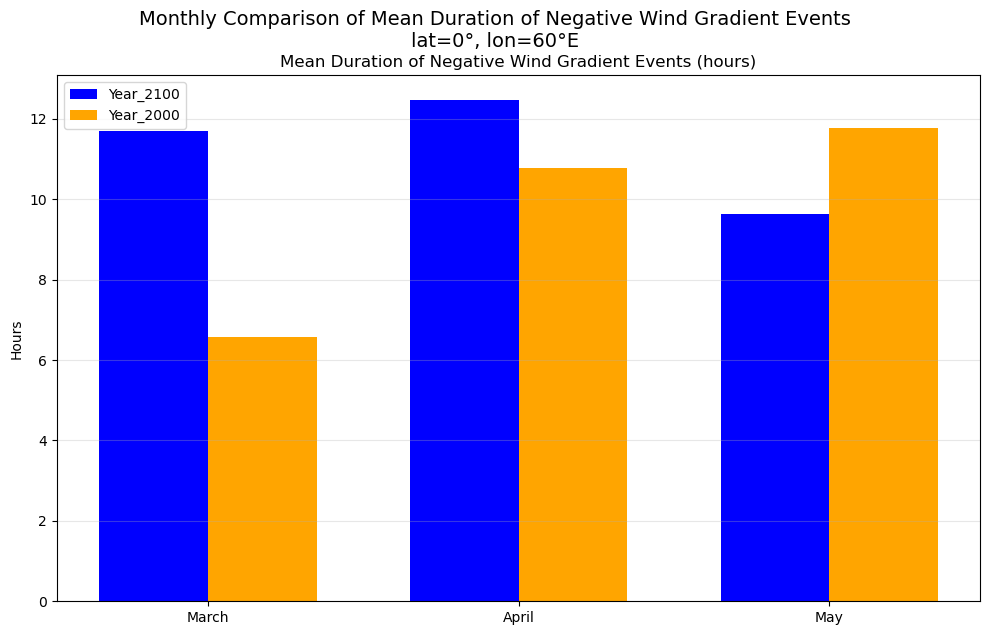

Analysis completed successfully!


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import glob

# Define constants for years
YEAR_2100 = 'Year_2100'
YEAR_2000 = 'Year_2000'

def process_dataset(ds, season_name, plotdata):
    """
    Process dataset to extract wind gradient data.
    This function is adapted from the original code.
    """
    lon = ds['lon']
    lat = ds['lat']
    lev = ds['lev']
    temp = ds['T']
    timee = ds['time']   
    
    U = ds['U']

    metal_ions = {}
    if all(var in ds for var in ['Fep', 'Mgp', 'Nap']):
        Fep = ds['Fep']
        Mgp = ds['Mgp']
        Nap = ds['Nap']
        Mp = Fep + 2*Mgp + Nap
        Mpdens = (Mp * 1e-6 * 100 * lev) / (1.380503e-23 * temp)
        metal_ions['Mp'] = Mp
        metal_ions['Mpdens'] = Mpdens
    
    #----------------------------------------------------
    # Changed to only use latitude 0 instead of -60 and 20
    lat_val = 0
    lat_idx = np.abs(lat - lat_val).argmin()
    
    lon_val = 60
    lon_idx = np.abs(lon - lon_val).argmin()
    
    alt_110_idx = 48
    
    plotdata[f'U_plot2_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_110_idx)
    
    if 'Mpdens' in metal_ions:
        plotdata[f'Mpdens_plot2_{lat_val}_{season_name}'] = metal_ions['Mpdens'].sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_110_idx)
    
    alt_113_idx = 47
    alt_108_idx = 49
    
    plotdata[f'U_plot2_113_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_113_idx)
    plotdata[f'U_plot2_108_{lat_val}_{season_name}'] = U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_108_idx)
    
    alt_120_idx = 43
    alt_100_idx = 52
    
    plotdata[f'U_plot2_120_100_{lat_val}_{season_name}'] = (
        (U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_120_idx)) - 
        (U.sel(lat=lat[lat_idx], lon=lon[lon_idx]).isel(lev=alt_100_idx))
    ) / 2e4  # wind shear is change in U / 20km   units = s-1

def process_spring_data(climate_path, smed_path):
    """
    Process only spring months (March, April, May) data
    """
    spring_months = ['03', '04', '05']
    Monthstr = ['Mar', 'Apr', 'May']
    season_name = 'spring'

    plotdata_all = {
        YEAR_2100: {}, 
        YEAR_2000: {}      
    }
    
    # Process climate data for spring
    file_paths = []
    for month in spring_months:
        pattern = climate_path.format(month=month)
        matched_files = glob.glob(pattern)
        print(f"Found {len(matched_files)} climate files for {month} using pattern: {pattern}")
        file_paths.extend(matched_files)
    
    print(f"Processing climate {season_name} season with {len(file_paths)} total files")
    if len(file_paths) > 0:
        ds = xr.open_mfdataset(file_paths, combine='by_coords')
        process_dataset(ds, season_name, plotdata_all[YEAR_2100])
    else:
        print(f"Warning: No climate files found for {season_name} season")
    
    # Process SMed data for spring if available
    if smed_path:
        file_paths = []
        for month in spring_months:
            pattern = smed_path.format(month=month)
            matched_files = glob.glob(pattern)
            print(f"Found {len(matched_files)} SMed files for {month} using pattern: {pattern}")
            file_paths.extend(matched_files)
        
        print(f"Processing SMed {season_name} season with {len(file_paths)} total files")
        if len(file_paths) > 0:
            ds = xr.open_mfdataset(file_paths, combine='by_coords')
            process_dataset(ds, season_name, plotdata_all[YEAR_2000])
        else:
            print(f"Warning: No SMed files found for {season_name} season")
    
    return plotdata_all

def analyze_monthly_negative_events(climate_data, smed_data, lat_val=0):  # Changed default lat_val to 0
    """
    Analyze negative wind gradient events by month (March, April, May)
    
    Parameters:
    -----------
    climate_data : dict
        Dictionary containing climate data
    smed_data : dict
        Dictionary containing SMed data
    lat_val : int
        Latitude value to analyze
        
    Returns:
    --------
    dict
        Dictionary with monthly statistics about negative wind gradient events
    """
    season = 'spring'
    key = f'U_plot2_120_100_{lat_val}_{season}'
    
    # Assuming each month has 30 days for simplicity
    month_ranges = {
        'March': (0, 30*24),
        'April': (30*24, 60*24), 
        'May': (60*24, 90*24)
    }
    
    results = {}
    
    for data_name, data in [(YEAR_2100, climate_data), (YEAR_2000, smed_data)]:
        if key in data:
            wind_data = data[key].values
            
            monthly_stats = {}
            
            for month_name, (start_hour, end_hour) in month_ranges.items():
                # Extract month data if available
                if len(wind_data) > start_hour:
                    month_data = wind_data[start_hour:min(end_hour, len(wind_data))]
                    
                    # Identify negative regions
                    negative_mask = month_data < 0
                    
                    if any(negative_mask):  # Only proceed if there are negative values
                        # Find the borders of negative regions
                        change_points = np.where(np.diff(np.concatenate(([False], negative_mask, [False]))))[0]
                        
                        # Group into start-end pairs
                        event_edges = [(change_points[i], change_points[i+1]-1) for i in range(0, len(change_points), 2)]
                        
                        # Calculate statistics for each event
                        event_stats = []
                        for start, end in event_edges:
                            event_data = month_data[start:end+1]
                            event_stats.append({
                                'start_hour': start + start_hour,
                                'end_hour': end + start_hour,
                                'duration_hours': end - start + 1,
                                'min_value': np.min(event_data),
                                'mean_value': np.mean(event_data),
                                'area': np.sum(event_data)  # Approximate integral of the negative region
                            })
                        
                        monthly_stats[month_name] = {
                            'num_events': len(event_stats),
                            'total_negative_hours': sum(e['duration_hours'] for e in event_stats),
                            'mean_duration': np.mean([e['duration_hours'] for e in event_stats]) if event_stats else 0,
                            'median_duration': np.median([e['duration_hours'] for e in event_stats]) if event_stats else 0,
                            'mean_min_value': np.mean([e['min_value'] for e in event_stats]) if event_stats else 0,
                            'events': event_stats
                        }
                    else:
                        monthly_stats[month_name] = {
                            'num_events': 0,
                            'total_negative_hours': 0,
                            'mean_duration': 0,
                            'median_duration': 0,
                            'mean_min_value': 0,
                            'events': []
                        }
                else:
                    monthly_stats[month_name] = {
                        'num_events': 0,
                        'total_negative_hours': 0,
                        'mean_duration': 0,
                        'median_duration': 0,
                        'mean_min_value': 0,
                        'events': []
                    }
            
            results[data_name] = monthly_stats
        else:
            print(f"Warning: Key '{key}' not found in {data_name} data")
    
    return results

def plot_mean_duration_comparison(analysis_results, figsize=(10, 6)):
    """
    Create a bar chart comparing only the mean duration of negative events by month
    """
    fig, ax = plt.subplots(figsize=figsize)
    
    months = ['March', 'April', 'May']
    metric = 'mean_duration'
    
    bar_width = 0.35
    index = np.arange(len(months))
    
    climate_values = []
    smed_values = []
    
    for month in months:
        if YEAR_2100 in analysis_results and month in analysis_results[YEAR_2100]:
            climate_values.append(analysis_results[YEAR_2100][month][metric])
        else:
            climate_values.append(0)
            
        if YEAR_2000 in analysis_results and month in analysis_results[YEAR_2000]:
            smed_values.append(analysis_results[YEAR_2000][month][metric])
        else:
            smed_values.append(0)
    
    ax.bar(index - bar_width/2, climate_values, bar_width, label=YEAR_2100, color='blue')
    ax.bar(index + bar_width/2, smed_values, bar_width, label=YEAR_2000, color='orange')
    
    ax.set_xticks(index)
    ax.set_xticklabels(months)
    ax.set_title('Mean Duration of Negative Wind Gradient Events (hours)')
    ax.set_ylabel('Hours')
    ax.grid(True, axis='y', alpha=0.3)
    ax.legend()
    
    plt.tight_layout()
    # Updated the title to reflect lat=0
    fig.suptitle('Monthly Comparison of Mean Duration of Negative Wind Gradient Events\nlat=0°, lon=60°E', 
                 y=1.05, fontsize=14)
    
    return fig, ax

# Example usage:
if __name__ == "__main__":
    # Example paths (uncomment and modify these to run the code)
    # climate_path = '/path/to/climate/data/file-{month}.nc'
    # smed_path = '/path/to/smed/data/file-{month}.nc'
    
    # Using the actual paths from the error message
    climate_path = '/resstore/b0243/Data/Sporadic_E/FX2100f19f19mg16NaFeMgiontransport_OUTPUT/hist/FX2100f19f19mg16NaFeMgiontransport.cam.h2.2100-{month}-*.nc'
    smed_path = '/resstore/b0243/Data/Sporadic_E/Solar_Med/archive_yr2000/ACP_CESM213_FX2000_f19_f19_mg16_Na_Fe_Mg_iontransport.cam.h2.0001-{month}-*.nc'
    
    spring_data = process_spring_data(climate_path, smed_path)
    
    # Analyze monthly negative events at latitude 0
    monthly_analysis = analyze_monthly_negative_events(spring_data[YEAR_2100], spring_data[YEAR_2000], lat_val=0)
    
    # Plot only mean duration comparison
    fig, ax = plot_mean_duration_comparison(monthly_analysis)
    plt.savefig('mean_duration_comparison_lat0.png')  # Updated filename to indicate lat=0
    plt.show()
    
    print("Analysis completed successfully!")